In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def apply_low_pass_filter(tensor, radius):
    """
    Aplica filtro passa-baixa em um tensor [C, H, W]
    Retorna o tensor filtrado e o espectro para visualização.
    """
    C, H, W = tensor.shape
    
    # 1. FFT e Shift para o centro
    freq_domain = torch.fft.fft2(tensor)
    freq_shifted = torch.fft.fftshift(freq_domain)

    # 2. Máscara Circular (Mantém o que está DENTRO do raio)
    cy, cx = H // 2, W // 2
    y, x = torch.meshgrid(torch.arange(H), torch.arange(W), indexing='ij')
    dist = torch.sqrt((x - cx)**2 + (y - cy)**2)
    mask = dist < radius
    
    # 3. Filtragem e Retorno ao domínio espacial
    freq_filtered = freq_shifted * mask.to(freq_shifted.device)
    freq_ishifted = torch.fft.ifftshift(freq_filtered)
    filtered = torch.fft.ifft2(freq_ishifted)
    
    # Retornamos a parte real e o espectro de magnitude (log) para o plot
    magnitude_spectrum = torch.log(1 + torch.abs(freq_shifted))
    return filtered.real, magnitude_spectrum

In [2]:
# Usando o caminho que você forneceu no seu código inicial
file_path = 'data/100/window_2003.npy' 

try:
    # Lógica exata do seu __init__: carregar, converter e pegar canais 2 e 3
    raw_data = np.load(file_path).astype(np.float32)
    # Pegamos o primeiro frame [0] e os canais [2:4] (U e V)
    # Shape resultante: [128, 128, 2] -> permute para [2, 128, 128]
    sample_uv = torch.from_numpy(raw_data[0, :, :, 2:4]).permute(2, 0, 1)
    
    print(f"Arquivo carregado: {file_path}")
    print(f"Shape do tensor para processamento: {sample_uv.shape}")
    
except FileNotFoundError:
    print(f"Erro: O arquivo {file_path} não foi encontrado no seu diretório.")

Arquivo carregado: data/100/window_2003.npy
Shape do tensor para processamento: torch.Size([2, 128, 128])


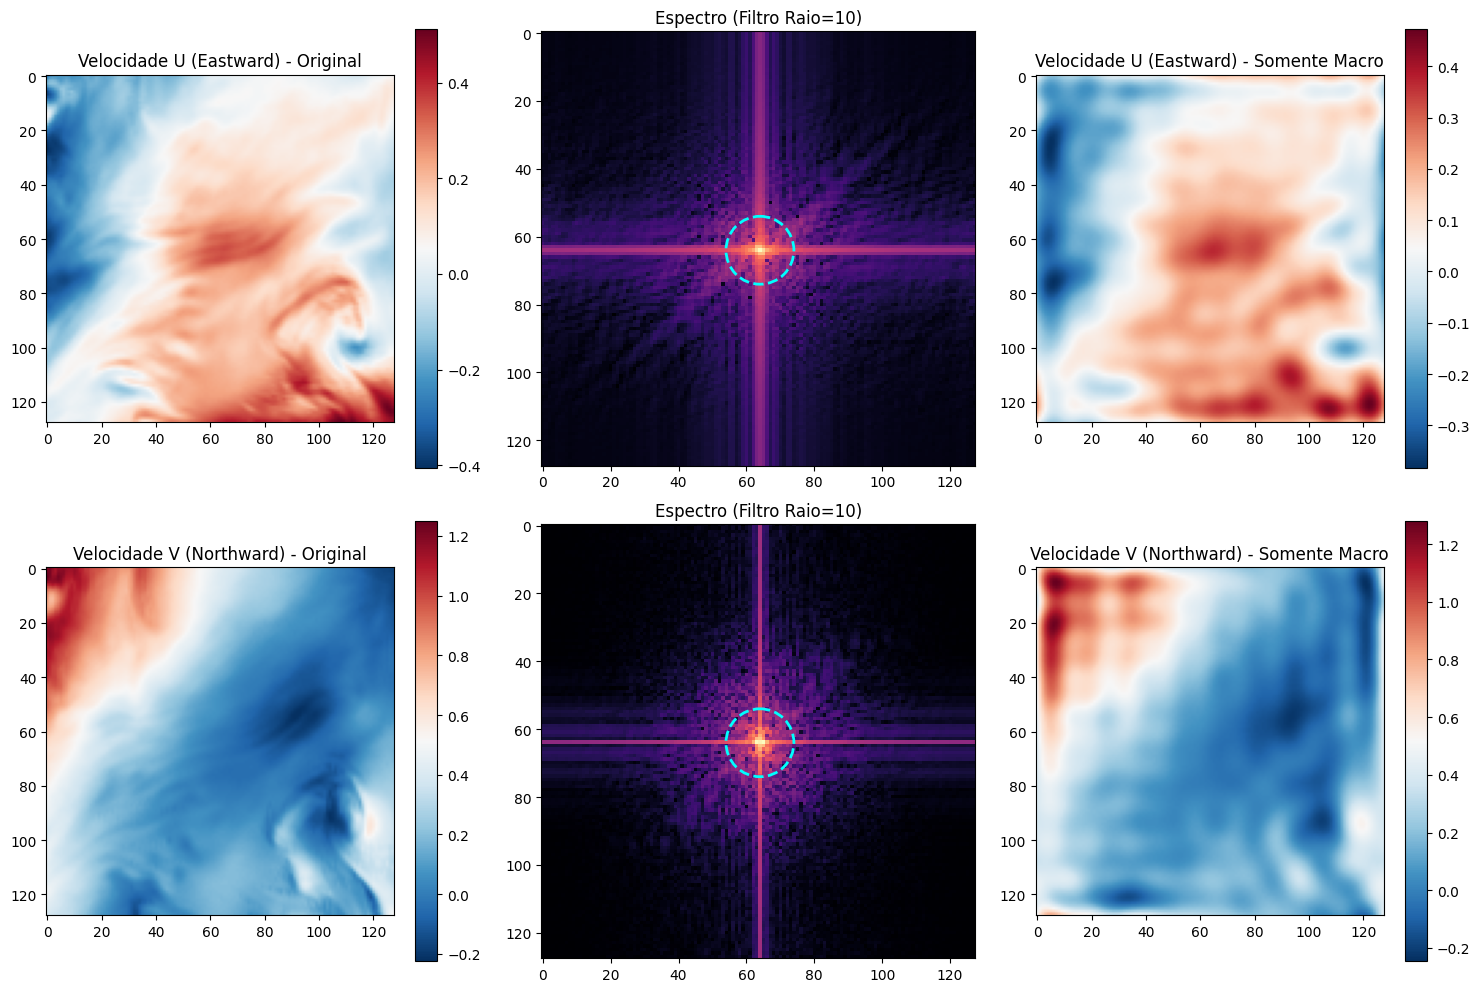

In [6]:
raio = 10 # Altere este valor para testar (5=muito macro, 40=detalhado)

filtrado, espectro = apply_low_pass_filter(sample_uv, raio)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Nomes para as linhas do plot
componentes = ['Velocidade U (Eastward)', 'Velocidade V (Northward)']

for i in range(2):
    # Coluna 1: Original (Seu dado vindo do .npy)
    im0 = axes[i, 0].imshow(sample_uv[i], cmap='RdBu_r')
    axes[i, 0].set_title(f"{componentes[i]} - Original")
    plt.colorbar(im0, ax=axes[i, 0])
    
    # Coluna 2: Espectro de Frequência (Onde o filtro atua)
    im1 = axes[i, 1].imshow(espectro[i], cmap='magma')
    circle = plt.Circle((64, 64), raio, color='cyan', fill=False, linestyle='--', linewidth=2)
    axes[i, 1].add_patch(circle)
    axes[i, 1].set_title(f"Espectro (Filtro Raio={raio})")
    
    # Coluna 3: Resultado Filtrado (Apenas fenômenos Macro)
    im2 = axes[i, 2].imshow(filtrado[i], cmap='RdBu_r')
    axes[i, 2].set_title(f"{componentes[i]} - Somente Macro")
    plt.colorbar(im2, ax=axes[i, 2])

plt.tight_layout()
plt.show()